# Active subspaces of CovidSim: cumulative COVID-19 deaths over 801 days, 51 uncertain inputs

Stored data from

W. Edeling, *On the deep active-subspace method*, SIAM/ASA Journal on Uncertainty Quantification
11(1):62–90, 2023. [doi:10.1137/21M1463240](https://doi.org/10.1137/21M1463240)

Wouter Edeling: Centrum Wiskunde & Informatica, Scientific Computing Group, Science Park 123, 1098XG Amsterdam,
The Netherlands.

Data: W. Edeling, *wedeling/deep_active_subspace_data*, https://github.com/wedeling/deep_active_subspace_data
(MIT licence; archived as [doi:10.5281/zenodo.7009160](https://doi.org/10.5281/zenodo.7009160), the paper's
reference [15]).

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import active_subspaces as ac

SEED = 132                        # the only seed: every bootstrap, permutation and split below draws from it
t_start = time.perf_counter()
warnings.simplefilter('ignore', ac.ValidityWarning)   # QPHD/OLS on a uniform space: discussed in the text
warnings.filterwarnings('ignore', message='The figure layout has changed')

## Summary

Edeling ran CovidSim, Imperial College's individual-based COVID-19 simulator, at 3000 Monte Carlo samples of
51 uniformly distributed inputs (intervention, disease, place and spatial-kernel parameters) and recorded the
cumulative death count; the quantity of interest is the count after 801 simulated days. No gradients exist,
so the notebook estimates the subspace from values with the global quadratic estimator (QPHD; the 3000 runs
exceed the 1378 coefficients of a full quadratic in 51 inputs), checked against the linear (OLS) and
local-linear (OPG) estimators and against a two-variable polynomial ridge fitted on held-out halves of the
data. One direction, dominated by the delay from the end of the latent period to symptom onset, explains a
linear-fit leave-one-out $R^2$ of 0.897 and $\lambda_1/\lambda_2 = 15.69$; a second direction (mostly the
proportion of symptomatic cases and the social-distancing spatial contact rate) raises the held-out $R^2$
from 0.903 to 0.953, which matches the paper's choice of a two-dimensional deep active subspace and its
eigenvalue pattern (Fig. 13).

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients the subspace is estimated from values: OLS fits $f \approx c + \mathbf{u}^\top
\mathbf{x}$ and takes $w_1 = \mathbf{u}/\|\mathbf{u}\|$ (one direction only); QPHD fits a quadratic
$q(\mathbf{x}) = c + \mathbf{g}^\top\mathbf{x} + \tfrac12 \mathbf{x}^\top \mathbf{H}\mathbf{x}$ and uses
$\mathbf{C} = \mathbf{g}\mathbf{g}^\top + \mathbf{H}\boldsymbol{\Sigma}\mathbf{H}$, the average outer
product of its gradient; OPG averages outer products of local linear gradients. See P. G. Constantine,
*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015,
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860). The paper's deep active subspace
(DAS) instead trains a neural network $\tilde f(\mathbf{x}) = \mathrm{NN}(\mathbf{W}_1^\top \mathbf{x})$ whose
first layer $\mathbf{W}_1$ is kept orthonormal by Gram–Schmidt, and shows the eigenvalues of
$\overline{\mathbf{C}}_{ANN} = \frac{1}{N}\sum_i \nabla\tilde f(\mathbf{x}_i)\nabla\tilde f(\mathbf{x}_i)^\top$
(eq. (4.5), p. 70).

## The model

**Simulator** (p. 80). CovidSim is "an influential individual-based simulation code developed by the MRC
centre for global infectious disease analysis at Imperial College London", used to explore
non-pharmaceutical interventions (paper ref. [18], Ferguson et al., Report 9, 2020). It simulates individuals
in households, schools, universities and workplaces (place types 0–3 in the input names) connected by a
spatial contact kernel; it has no closed-form equations, and the article states none. The article does not
name the simulated country or region, the population files or the intervention scenario, and neither does
the authors' data repository; what is known about the population is only what the inputs and outputs show
(the place types, an active intervention scenario, 27,659 to 142,155 deaths after 801 days; see `DATA.md`).
The article cites a previous study by the author's group, which applied dimension-adaptive stochastic
collocation to the same code with 19 uncertain inputs (ref. [16], Edeling et al., *Nature Computational
Science* 1:128–135, 2021); its setting is not evidence for the setting of these runs.

**Inputs** ($m = 51$; p. 80). "We will consider a case with D = 51 continuous input parameters, for which we
prescribe uniform input distributions." The article refers to its supplementary materials for the table of
inputs, defaults and ranges; the ranges used here are the `cp.Uniform(lower, upper)` entries of the authors'
EasyVVUQ file `COVID19/vary.py`, whose 51 active entries match the 51 stored columns in order (every stored
value lies inside its range; the load cell prints the share of each range the samples span). Eleven further
entries of `vary.py` are commented out (four discrete quarantine and isolation delays and durations, the
reproduction number, the infectious period, four place group sizes and `CLP1`); they were not varied, and
their values in the runs are not recorded. The groups below are those
of the comments in `vary.py`. Units: days for the latent period and the symptom delay and metres for the
kernel scales follow the CovidSim parameter-file conventions (an inference: neither the article nor `vary.py`
gives units); every other input is a dimensionless ratio, proportion, factor or exponent.

**Quantity of interest** (p. 81). "The QoI we used here is the predicted cumulative death count after a
simulated time of 801 days" (Fig. 14 caption: "the final cumulative death count after 801 days"), in persons.
The stored output has 801 daily columns per run; the QoI is the last one, as in the authors' notebook
(`samples[:, -1]`).

**Design** (p. 81). "We sampled the input space with 3000 MC evaluations", an EasyVVUQ Monte Carlo design
(independent uniform draws; seed not reported), run on the Altair supercomputer at the Poznan Supercomputing
and Networking Center (the authors' repository notebook names the "Eagle" supercomputer instead; this notebook
follows the article): 28 cores and about 10 minutes per run, about 14,000 core-hours in all. The paper trains
DAS on 50 % of the runs and validates on the other 1500 (Fig. 14).

**Gradients.** None: CovidSim computes none, and the paper's method is gradient-free.

The table printed below lists the 51 inputs with their groups, units and uniform ranges as stored in
`covidsim_input_ranges.csv` (column order of `covidsim_inputs.csv`).

In [2]:
# Input names and ranges, as stored (column order of vary.py in the authors' repository)
with open('covidsim_inputs.csv') as fh:
    fh.readline()
    header = fh.readline()[2:].strip().split(',')
names = [h.split(' [')[0] for h in header]
units = [h.split(' [')[1].rstrip(']') for h in header]
lo, hi = np.loadtxt('covidsim_input_ranges.csv', delimiter=',')
GROUPS = ['intervention'] * 10 + ['disease'] * 12 + ['spatial / place'] * 15 + ['kernel / place links'] * 14
print(f'{"#":>3} {"input":<68} {"group":<21} {"units":<5} {"lower":>9} {"upper":>9}')
for i, (n, g, u, a, b) in enumerate(zip(names, GROUPS, units, lo, hi)):
    print(f'{i + 1:>3} {n:<68} {g:<21} {u:<5} {a:>9.4g} {b:>9.4g}')

  # input                                                                group                 units     lower     upper
  1 Relative_household_contact_rate_after_closure                        intervention          1           1.2       1.8
  2 Relative_spatial_contact_rate_after_closure                          intervention          1             1       1.5
  3 Relative_household_contact_rate_after_quarantine                     intervention          1           1.6       2.4
  4 Residual_spatial_contacts_after_household_quarantine                 intervention          1           0.2       0.3
  5 Household_level_compliance_with_quarantine                           intervention          1           0.5       0.9
  6 Individual_level_compliance_with_quarantine                          intervention          1           0.9         1
  7 Proportion_of_detected_cases_isolated                                intervention          1           0.6       0.8
  8 Residual_contacts_after_case

## Load the data

All files are read with numpy. `covidsim_cumulative_deaths_daily.npz` holds the whole daily series of every
run; the notebook uses its last column, which equals `covidsim_deaths_day801.csv`. Inputs are mapped linearly
to $[-1, 1]$ through their uniform ranges (the input space does this; the same scaling as the authors'
notebook).

In [3]:
X = np.loadtxt('covidsim_inputs.csv', delimiter=',')            # (3000, 51) physical units
f = np.loadtxt('covidsim_deaths_day801.csv', delimiter=',')     # (3000,) cumulative deaths, persons
with np.load('covidsim_cumulative_deaths_daily.npz') as daily:
    deaths, day = daily['deaths'], daily['day']                  # (3000, 801) and (801,)
M, m = X.shape
space = ac.Uniform(lo, hi, names=names)
Z = space.to_normalized(X)                                      # each input mapped linearly to [-1, 1]
print('X', X.shape, ' f', f.shape, ' daily deaths', deaths.shape, ' days', day[0], '...', day[-1])
print('f = last daily column:', np.array_equal(f, deaths[:, -1]))
print('inputs inside their ranges:', bool(np.all((X >= lo) & (X <= hi))), ' distinct rows:', len(np.unique(X, axis=0)))
print(f'deaths at day 801: min {f.min():.0f}, median {np.median(f):.0f}, mean {f.mean():.1f}, max {f.max():.0f}, '
      f'sd {f.std(ddof=1):.1f}')
cover = (X.max(0) - X.min(0)) / (hi - lo)
print(f'share of each input range spanned by the samples: {cover.min():.4f} to {cover.max():.4f}')
print('every run non-decreasing in time:', bool(np.all(np.diff(deaths, axis=1) >= 0)))
print(f'deaths added in the last 100 days: median share {np.median((deaths[:, -1] - deaths[:, -101]) / deaths[:, -1]):.4f}')
# uniformity of the Monte Carlo design: share of each input's range covered, and mean / sd in normalized units
print(f'normalized inputs: mean in [{Z.mean(0).min():.3f}, {Z.mean(0).max():.3f}], '
      f'sd in [{Z.std(0).min():.3f}, {Z.std(0).max():.3f}] (uniform: 0 and {1/np.sqrt(3):.3f})')

X (3000, 51)  f (3000,)  daily deaths (3000, 801)  days 1 ... 801
f = last daily column: True
inputs inside their ranges: True  distinct rows: 3000
deaths at day 801: min 27659, median 69999, mean 71356.5, max 142155, sd 19848.9
share of each input range spanned by the samples: 0.9980 to 0.9999
every run non-decreasing in time: True
deaths added in the last 100 days: median share 0.0954
normalized inputs: mean in [-0.015, 0.024], sd in [0.564, 0.586] (uniform: 0 and 0.577)


## Estimate the subspace

**Estimator.** There are no gradients, so the subspace is estimated from the $M = 3000$ values. The full
quadratic in $m = 51$ inputs has $(m+1)(m+2)/2 = 1378$ coefficients, fewer than the 3000 runs, so QPHD can be
used on all of them; it is the primary estimator because, unlike OLS, it gives more than one eigenvalue and
so a gap to compare with the paper's Fig. 13. Three checks follow. (1) OLS, the linear fit, gives the first
direction alone. (2) With 1378 coefficients the quadratic is fitted with little to spare: the cell below fits
it on a random half and tests it on the other, and a permutation null shows how large QPHD eigenvalues get
from noise alone. (3) OPG (local linear gradients on the $\lfloor 1.7m \rfloor = 86$ nearest runs of every
run) needs no global model. QPHD and OLS assume Gaussian inputs in their derivation (the library warns on a
uniform space; the warning is silenced here), which is one more reason the dimension is checked below with a
model fitted on held-out data. All bootstraps use 200 replicates, and every random draw derives from `SEED`.

In [4]:
# Linear fit (OLS direction) with its leave-one-out R^2 (closed form through the hat matrix)
A1 = np.column_stack([np.ones(M), Z])
c1, *_ = np.linalg.lstsq(A1, f, rcond=None)
H1 = A1 @ np.linalg.solve(A1.T @ A1, A1.T)
loo_res = (f - A1 @ c1) / (1.0 - np.diag(H1))
print(f'linear fit: R^2 {1 - np.var(f - A1 @ c1) / np.var(f):.3f}, LOO R^2 {1 - np.mean(loo_res**2) / np.var(f):.3f}')

sub_ols = ac.active_subspace(space=space, X=X, f=f, estimator='ols', n=1, nboot=200, rng=SEED,
                             bootstrap_vectors=1)
d_ols = sub_ols.bootstrap_distances[:, 0]
print(f'OLS: bootstrap distance of w1 (200 replicates): mean {d_ols.mean():.3f}, 95th percentile {np.quantile(d_ols, 0.95):.3f}')

# Full quadratic in all 51 inputs: (m+1)(m+2)/2 coefficients, fitted on a random half and tested on the other
nq = (m + 1) * (m + 2) // 2
ju, ku = np.triu_indices(m, k=1)
def quad_design(Zs):
    return np.hstack([np.ones((len(Zs), 1)), Zs, Zs**2, Zs[:, ju] * Zs[:, ku]])
rng = np.random.default_rng(SEED)
perm = rng.permutation(M)
tr, te = perm[:M // 2], perm[M // 2:]
cq, *_ = np.linalg.lstsq(quad_design(Z[tr]), f[tr], rcond=None)
cq_all, *_ = np.linalg.lstsq(quad_design(Z), f, rcond=None)
print(f'full quadratic: {nq} coefficients; R^2 on all {M} runs {1 - np.var(f - quad_design(Z) @ cq_all) / np.var(f):.3f}; '
      f'fitted on {len(tr)}, test R^2 {1 - np.mean((f[te] - quad_design(Z[te]) @ cq)**2) / np.var(f[te]):.3f}')

linear fit: R^2 0.900, LOO R^2 0.897


OLS: bootstrap distance of w1 (200 replicates): mean 0.043, 95th percentile 0.051


full quadratic: 1378 coefficients; R^2 on all 3000 runs 0.983; fitted on 1500, test R^2 0.546


In [5]:
t0 = time.perf_counter()
sub = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', n=2, nboot=200, rng=SEED, bootstrap_vectors=2)
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=2)   # sign rule: f increases along w1 and w2
lam = sub.eigenvalues
print(f'QPHD on M = {M} runs ({nq} quadratic coefficients), 200 bootstrap replicates: {time.perf_counter() - t0:.0f} s')
print('lambda_k / lambda_1, k = 1..8:', np.array2string(lam[:8] / lam[0], precision=4))
print('ratios lambda_k / lambda_(k+1), k = 1..6:', np.array2string(lam[:6] / lam[1:7], precision=2))
bl = sub.bootstrap_eigenvalues
for k in range(4):
    r = bl[:, k] / bl[:, k + 1]
    print(f'  lambda_{k + 1}/lambda_{k + 2}: 95% bootstrap interval [{np.quantile(r, 0.025):.2f}, {np.quantile(r, 0.975):.2f}]')
dist = sub.bootstrap_distances
print('mean bootstrap subspace distance, n = 1..5:', np.array2string(dist[:, :5].mean(0), precision=3))
print(f'|w1(QPHD) . w1(OLS)| = {abs(sub.W[:, 0] @ sub_ols.W[:, 0]):.4f}')
print(f'share of trace(C) in the first 1, 2, 3 eigenvalues: '
      f'{lam[0] / lam.sum():.3f}, {lam[:2].sum() / lam.sum():.3f}, {lam[:3].sum() / lam.sum():.3f}')

QPHD on M = 3000 runs (1378 quadratic coefficients), 200 bootstrap replicates: 118 s
lambda_k / lambda_1, k = 1..8: [1.     0.0637 0.0214 0.0087 0.0045 0.004  0.0039 0.0034]
ratios lambda_k / lambda_(k+1), k = 1..6: [15.69  2.98  2.46  1.95  1.12  1.01]
  lambda_1/lambda_2: 95% bootstrap interval [13.06, 16.49]
  lambda_2/lambda_3: 95% bootstrap interval [1.94, 3.29]
  lambda_3/lambda_4: 95% bootstrap interval [1.27, 2.32]
  lambda_4/lambda_5: 95% bootstrap interval [1.02, 1.44]
mean bootstrap subspace distance, n = 1..5: [0.05  0.216 0.398 0.774 0.94 ]
|w1(QPHD) . w1(OLS)| = 0.9990
share of trace(C) in the first 1, 2, 3 eigenvalues: 0.870, 0.925, 0.944


In [6]:
# Two permutation nulls for QPHD, 20 replicates each. (a) f with its rows shuffled: no relation to X at all,
# so the eigenvalues are what 1378 least-squares coefficients fitted to 3000 values of variance var(f) reach by
# chance. (b) The residuals of a cubic in the two QPHD active variables, shuffled: the level that noise of the
# size actually left in the data reaches.
sur3 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=3)
resid = f - ac.predict(sur3, X)
print(f'residual variance of the cubic in (y1, y2): {np.var(resid) / np.var(f):.4f} of var(f)')
rng = np.random.default_rng(SEED + 1)
null_f, null_r = [], []
for b in range(20):
    null_f.append(ac.active_subspace(space=space, X=X, f=rng.permutation(f), estimator='qphd', n=1).eigenvalues[0])
    null_r.append(ac.active_subspace(space=space, X=X, f=rng.permutation(resid), estimator='qphd', n=1).eigenvalues[0])
null_f, null_r = np.array(null_f), np.array(null_r)
print(f'(a) shuffled f: null lambda_1 / data lambda_1 in [{null_f.min() / lam[0]:.4f}, {null_f.max() / lam[0]:.4f}]')
print(f'(b) shuffled residuals: null lambda_1 / data lambda_1 in [{null_r.min() / lam[0]:.4f}, {null_r.max() / lam[0]:.4f}]')
print('data lambda_k / lambda_1, k = 2..6:', np.array2string(lam[1:6] / lam[0], precision=4))
print(f'data eigenvalues above the largest null lambda_1: (a) {int(np.sum(lam > null_f.max()))}, '
      f'(b) {int(np.sum(lam > null_r.max()))}')

# Local linear check (OPG: local linear gradients on the 86 nearest runs of each run)
sub_opg = ac.active_subspace(space=space, X=X, f=f, estimator='opg', n=2)
lo_ = sub_opg.eigenvalues
print('OPG lambda_k / lambda_1, k = 1..5:', np.array2string(lo_[:5] / lo_[0], precision=4))
print(f'|w1(OPG) . w1(QPHD)| = {abs(sub_opg.W[:, 0] @ sub.W[:, 0]):.4f}; '
      f'cos of largest principal angle between the 2-D subspaces = '
      f'{np.linalg.svd(sub_opg.W[:, :2].T @ sub.W[:, :2], compute_uv=False).min():.3f}')

residual variance of the cubic in (y1, y2): 0.0437 of var(f)


(a) shuffled f: null lambda_1 / data lambda_1 in [0.1243, 0.1796]
(b) shuffled residuals: null lambda_1 / data lambda_1 in [0.0051, 0.0080]
data lambda_k / lambda_1, k = 2..6: [0.0637 0.0214 0.0087 0.0045 0.004 ]
data eigenvalues above the largest null lambda_1: (a) 1, (b) 4


OPG lambda_k / lambda_1, k = 1..5: [1.     0.0099 0.0046 0.0045 0.0044]
|w1(OPG) . w1(QPHD)| = 0.9990; cos of largest principal angle between the 2-D subspaces = 0.978


## Results

QPHD eigenvalues with their 95 % bootstrap band (left) and the bootstrap subspace distance for each
dimension (right); the numbers are printed above, the text follows the figure.

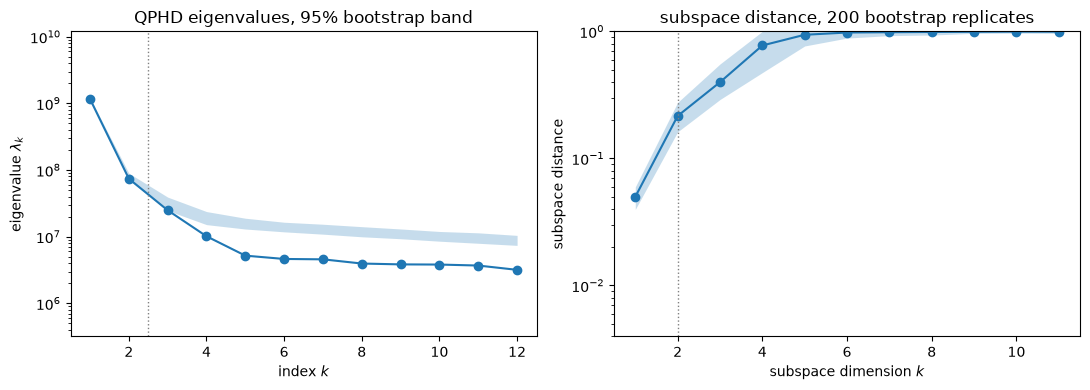

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, interval='percentile', k_max=12, ax=axs[0])
axs[0].set_title('QPHD eigenvalues, 95% bootstrap band')
ac.plotting.plot_subspace_errors(sub, interval='percentile', k_max=11, ax=axs[1])
axs[1].set_title('subspace distance, 200 bootstrap replicates')
fig.tight_layout()
plt.close(fig)
fig

**Linear fit and OLS.** A linear function of the 51 inputs explains $R^2$ 0.900 of the variance of the
deaths (leave-one-out $R^2$ 0.897), and the OLS direction is stable (mean bootstrap distance 0.043). The full
quadratic reaches $R^2$ 0.983 on all 3000 runs but only 0.546 on a held-out half when fitted on the other
half: its 1378 coefficients overfit, so QPHD's trailing eigenvalues carry fitting noise, which the nulls
below quantify.

**QPHD eigenvalues.** $\lambda_2/\lambda_1 = 0.0637$, $\lambda_3/\lambda_1 = 0.0214$; the ratios of
consecutive eigenvalues are 15.69, 2.98, 2.46, 1.95, 1.12. The gap after $\lambda_1$ is clear (bootstrap
interval [13.06, 16.49]); the next two ratios are comparable (intervals [1.94, 3.29] and [1.27, 2.32]
overlap), so the eigenvalues alone do not separate $n = 2$ from $n = 3$. The mean bootstrap subspace distance
is 0.05 for $n = 1$, 0.216 for $n = 2$ and 0.398 for $n = 3$. The first eigenvalue holds 0.870 of the trace
of $\mathbf{C}$, the first two 0.925.

**Nulls and OPG.** Shuffling $f$ gives null eigenvalues up to 0.1796 of $\lambda_1$, larger than the data's
$\lambda_2$: with all of var(f) as noise the quadratic fit alone produces eigenvalues of that size, so only
$\lambda_1$ is above this level. Noise of the size actually left by a cubic in the first two active
variables (0.0437 of var(f)), shuffled, gives null eigenvalues 0.0051–0.0080 of $\lambda_1$; $\lambda_2$
(0.0637) and $\lambda_3$ (0.0214) are well above that, $\lambda_4$ (0.0087) is just above it, and the rest are
at the noise level. OPG finds the same first direction ($|w_1^\top w_1^{OPG}| = 0.9990$) and nearly the same
two-dimensional subspace (cosine of the largest principal angle 0.978), with a much smaller
$\lambda_2/\lambda_1 = 0.0099$: on 86 neighbours in 51 dimensions the local fits are nearly global linear fits,
which damps the curvature that the second direction carries.

The bootstrap band of the eigenvalue plot lies above the estimates from $k = 3$ on; resampling with
replacement repeats rows, which increases the fitting noise of the quadratic, so the band shows the variability
but is biased upward there.

**Eigenvectors** (normalized inputs; signs set by `ac.orient(..., by='covariance')`, so that $f$ increases
along $w_1$ and $w_2$; the paper prints no eigenvectors, so its signs cannot be matched, and since
corr$(f, y_2)$ is only 0.040 (printed with the sufficient summary plots) the sign of $w_2$ is close to arbitrary).
The cell prints the six largest weights of each vector with the input number of the table above.

w1: 17 Delay_from_end_of_latent_period_to_start_of_symptoms +0.817, 10 Relative_spatial_contact_rate_given_social_distancing +0.334, 13 Latent_period -0.314, 12 Proportion_symptomatic -0.208, 5 Household_level_compliance_with_quarantine -0.197, 32 Relative_place_contact_rate_given_social_distancing_by_place_type3 +0.099
w2: 12 Proportion_symptomatic -0.767, 10 Relative_spatial_contact_rate_given_social_distancing -0.455, 13 Latent_period +0.295, 32 Relative_place_contact_rate_given_social_distancing_by_place_type3 -0.186, 17 Delay_from_end_of_latent_period_to_start_of_symptoms +0.157, 11 Symptomatic_infectiousness_relative_to_asymptomatic -0.108
largest |weight| of inputs 33-51 in w1, w2: 0.050, 0.040
input 14 Mortality_factor: w1 -0.004, w2 -0.022; corr with f 0.032


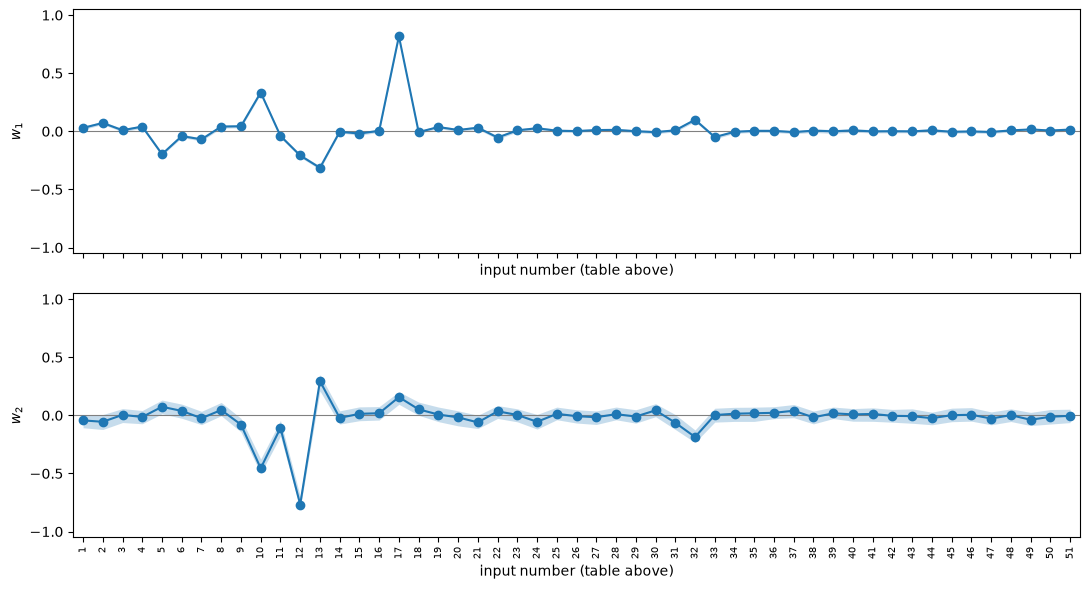

In [8]:
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=[str(i + 1) for i in range(m)],
                                         interval='percentile', figsize=(11, 6))
for ax in axs:
    ax.tick_params(axis='x', labelsize=7)
    ax.set_xlabel('input number (table above)')
fig.tight_layout()
for j in range(2):
    w = sub.W[:, j]
    top = np.argsort(-np.abs(w))[:6]
    print(f'w{j + 1}: ' + ', '.join(f'{i + 1} {names[i]} {w[i]:+.3f}' for i in top))
print(f'largest |weight| of inputs 33-51 in w1, w2: {np.abs(sub.W[32:, 0]).max():.3f}, {np.abs(sub.W[32:, 1]).max():.3f}')
j = names.index('Mortality_factor')
print(f'input {j + 1} {names[j]}: w1 {sub.W[j, 0]:+.3f}, w2 {sub.W[j, 1]:+.3f}; corr with f {np.corrcoef(Z[:, j], f)[0, 1]:.3f}')
plt.close(fig)
fig

corr(f, y1) = 0.948; corr(f, y2) = 0.040


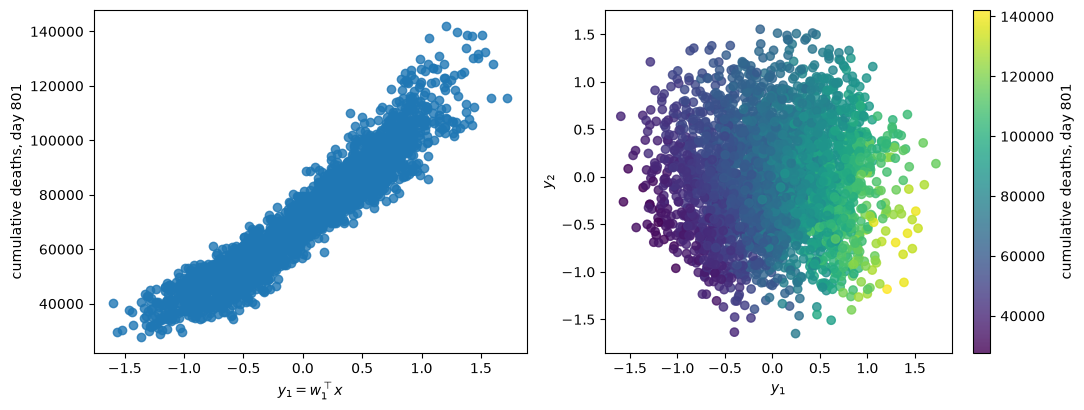

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='cumulative deaths, day 801', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label='cumulative deaths, day 801', ax=axs[1])
fig.tight_layout()
Y = Z @ sub.W[:, :2]
plt.close(fig)
print(f'corr(f, y1) = {np.corrcoef(f, Y[:, 0])[0, 1]:.3f}; corr(f, y2) = {np.corrcoef(f, Y[:, 1])[0, 1]:.3f}')
fig

The first direction is dominated by input 17, the delay from the end of the latent period to the start of
symptoms (+0.817), with the spatial contact rate under social distancing (input 10, +0.334), the latent period
(13, −0.314), the proportion symptomatic (12, −0.208) and household compliance with quarantine (5, −0.197):
deaths rise with a later symptom onset and with more contacts under distancing, and fall with a longer latent
period, a larger symptomatic share and better household compliance. (A plausible reading, not the paper's:
symptoms trigger case isolation and household quarantine in the simulated scenario, so a later onset leaves
more transmission before they act.) The
second direction is mostly the proportion symptomatic (−0.767) and the distancing contact rate (−0.455),
with the latent period (+0.295). Inputs 33–51 (random contacts and place attendance when symptomatic, spatial kernel
and place-link parameters) have no weight above 0.050 in $w_1$ or 0.040 in $w_2$ (printed above). The sufficient summary plot against $y_1$ is nearly linear
(corr$(f, y_1) = 0.948$) with a spread that grows at large $y_1$; the two-variable plot shows that this
spread is ordered by $y_2$, i.e. the second direction matters most where deaths are high.

### Choosing the dimension

The eigenvalue ratios leave $n = 2$ and $n = 3$ close, so the dimension is chosen by prediction on held-out
runs, as the paper does (it chose $d = 2$ because "$d = 1$ yielded relatively high training and test errors",
p. 81). For 10 random 1500/1500 splits, the cell below fits on one half a polynomial ridge function
$f \approx g(\mathbf{W}^\top\mathbf{x})$, $g$ a cubic in $d$ variables and $\mathbf{W}$ orthonormal, with
$\mathbf{W}$ optimized from the QPHD directions of that half (a deterministic counterpart of DAS with $d$
active variables), and tests it on the other half, with $R^2$ and the paper's relative error, eq. (8.2), p. 75:
$e = \frac{1}{T}\sum_i |f(\mathbf{x}_i) - \tilde f(\mathbf{x}_i)|/|f(\mathbf{x}_i)| \times 100$.

In [10]:
# Polynomial ridge approximation f ~ g(W^T z), g a cubic in d variables, W (m x d) orthonormal, fitted by
# variable projection: for each W the coefficients of g are the least-squares solution, and W is optimized
# (L-BFGS on an unconstrained m x d matrix, orthonormalized by QR) from the leading QPHD eigenvectors.
from itertools import combinations_with_replacement
def cubic(Y):
    cols = [np.ones(len(Y))]
    for k in (1, 2, 3):
        cols += [np.prod(Y[:, list(c)], axis=1) for c in combinations_with_replacement(range(Y.shape[1]), k)]
    return np.column_stack(cols)

def ridge_fit(Ztr, ftr, W0):
    shape = W0.shape
    def loss(v):
        Q, _ = np.linalg.qr(v.reshape(shape))
        B = cubic(Ztr @ Q)
        c, *_ = np.linalg.lstsq(B, ftr, rcond=None)
        return np.mean((ftr - B @ c)**2) / np.var(ftr)
    res = minimize(loss, W0.ravel(), method='L-BFGS-B', options={'maxiter': 300})
    Q, _ = np.linalg.qr(res.x.reshape(shape))
    c, *_ = np.linalg.lstsq(cubic(Ztr @ Q), ftr, rcond=None)
    return Q, c

def rel_err(y, yhat):          # the paper's error measure, eq. (8.2), in percent
    return 100 * np.mean(np.abs(y - yhat) / np.abs(y))

t0 = time.perf_counter()
rng = np.random.default_rng(SEED + 2)
splits = [rng.permutation(M) for _ in range(10)]
ridge = {d: [] for d in (1, 2, 3)}
lin = []
for p in splits:
    tr, te = p[:M // 2], p[M // 2:]
    sub_tr = ac.active_subspace(space=space, X=X[tr], f=f[tr], estimator='qphd', n=3)
    a, *_ = np.linalg.lstsq(A1[tr], f[tr], rcond=None)
    lin.append((1 - np.mean((f[te] - A1[te] @ a)**2) / np.var(f[te]), rel_err(f[te], A1[te] @ a)))
    for d in (1, 2, 3):
        Q, c = ridge_fit(Z[tr], f[tr], sub_tr.W[:, :d])
        pred_te, pred_tr = cubic(Z[te] @ Q) @ c, cubic(Z[tr] @ Q) @ c
        cosang = np.linalg.svd(Q.T @ sub.W[:, :d], compute_uv=False).min()
        ridge[d].append((1 - np.mean((f[te] - pred_te)**2) / np.var(f[te]), rel_err(f[te], pred_te),
                         rel_err(f[tr], pred_tr), cosang))
print(f'10 random 1500/1500 splits ({time.perf_counter() - t0:.0f} s); mean [min, max] over splits')
lin = np.array(lin)
print(f'  linear in all 51 inputs: test R^2 {lin[:, 0].mean():.3f} [{lin[:, 0].min():.3f}, {lin[:, 0].max():.3f}], '
      f'test e {lin[:, 1].mean():.2f}% [{lin[:, 1].min():.2f}, {lin[:, 1].max():.2f}]')
for d in (1, 2, 3):
    r = np.array(ridge[d])
    print(f'  cubic ridge d = {d}: test R^2 {r[:, 0].mean():.3f} [{r[:, 0].min():.3f}, {r[:, 0].max():.3f}], '
          f'test e {r[:, 1].mean():.2f}% [{r[:, 1].min():.2f}, {r[:, 1].max():.2f}], train e {r[:, 2].mean():.2f}%, '
          f'cos of largest angle to the full-data QPHD W1 (d columns) {r[:, 3].mean():.3f}')

10 random 1500/1500 splits (205 s); mean [min, max] over splits
  linear in all 51 inputs: test R^2 0.893 [0.890, 0.898], test e 7.44% [7.23, 7.64]
  cubic ridge d = 1: test R^2 0.903 [0.898, 0.906], test e 7.18% [6.95, 7.43], train e 6.90%, cos of largest angle to the full-data QPHD W1 (d columns) 0.998
  cubic ridge d = 2: test R^2 0.953 [0.948, 0.957], test e 4.71% [4.60, 4.87], train e 4.40%, cos of largest angle to the full-data QPHD W1 (d columns) 0.983
  cubic ridge d = 3: test R^2 0.958 [0.948, 0.964], test e 4.53% [4.26, 4.96], train e 4.01%, cos of largest angle to the full-data QPHD W1 (d columns) 0.626


In [11]:
# Surrogate on the two QPHD active variables (all 3000 runs), cubic polynomial, leave-one-out R^2
for deg in (2, 3, 4):
    sur = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=deg)
    print(f'polynomial of degree {deg} in (y1, y2): LOO R^2 {sur.loo_r_squared:.3f}')
sub1 = ac.with_dimension(sub, 1)
for deg in (1, 2, 3):
    sur = ac.fit_surrogate(X=X, f=f, subspace=sub1, kind='poly', degree=deg)
    print(f'polynomial of degree {deg} in y1 only: LOO R^2 {sur.loo_r_squared:.3f}')

polynomial of degree 2 in (y1, y2): LOO R^2 0.953
polynomial of degree 3 in (y1, y2): LOO R^2 0.956
polynomial of degree 4 in (y1, y2): LOO R^2 0.957
polynomial of degree 1 in y1 only: LOO R^2 0.898
polynomial of degree 2 in y1 only: LOO R^2 0.906
polynomial of degree 3 in y1 only: LOO R^2 0.907


On held-out runs the linear model in all 51 inputs has $R^2$ 0.893 and the one-variable cubic ridge 0.903
(test error $e$ 7.18 %). Two variables raise $R^2$ to 0.953 (range 0.948–0.957 over the splits) and lower
$e$ to 4.71 %; a third adds only 0.005 (0.958) and its fitted subspace is unstable (cosine of the largest
principal angle to the full-data QPHD subspace 0.627, against 0.983 for $d = 2$). On all 3000 runs a cubic in
the two QPHD active variables has leave-one-out $R^2$ 0.956 (the subspace itself fitted on all runs, so this
is slightly optimistic), against 0.907 for a cubic in $y_1$ alone. **The notebook therefore takes $n = 2$**:
the gap after $\lambda_1$ is clear, the second direction adds 0.05 of held-out $R^2$ with a stable subspace,
and the third neither improves prediction materially nor is stable.

## Comparison with the paper

The paper's eigenvalues are those of the DAS network (Fig. 13, $d = 5$, plotted on a log axis without
printed values); the values used below were read from the published figure and are approximate. Its errors
are means over 100 replica networks (Fig. 15), taken from the authors' file `errors_n_neurons10.hdf5`. The
input ranking is from the authors' repository notebook (a derivative-based sensitivity of the DAS network,
marked there "not in article").

In [12]:
# Published values. Fig. 13 (p. 81) shows the five nonzero DAS eigenvalues (d = 5) as points on a log axis;
# the values below were read from the published figure (approximate). Fig. 15 (p. 82): mean DAS errors over
# 100 replica networks, as stored in the authors' file errors_n_neurons10.hdf5 (1500 training runs).
FIG13 = np.array([2.95, 0.219, 0.052, 0.041, 0.020])
DAS_TEST_E_1500, DAS_TRAIN_E_1500, DAS_TEST_E_2700 = 5.84, 5.42, 4.95
# Input ranking of the authors' repository notebook (COVID19.ipynb, 'Global derivative-based sensitivity
# plots (not in article)'), DAS network, 0-based column numbers, first ten:
DAS_REPO_RANK = [16, 9, 12, 11, 4, 31, 6, 1, 21, 10]

C = sub.eigenvectors @ np.diag(lam) @ sub.eigenvectors.T     # QPHD matrix
rank_q = list(np.argsort(-np.diag(C))[:10])
r2 = np.array(ridge[2])
rows = [
    ('lambda_2 / lambda_1', 'Fig. 13, p. 81 (read)', f'{FIG13[1] / FIG13[0]:.3f}', f'{lam[1] / lam[0]:.3f}'),
    ('lambda_3 / lambda_1', 'Fig. 13, p. 81 (read)', f'{FIG13[2] / FIG13[0]:.4f}', f'{lam[2] / lam[0]:.4f}'),
    ('lambda_1 / lambda_2', 'Fig. 13 ("small gap after lambda_1")', f'{FIG13[0] / FIG13[1]:.1f}', f'{lam[0] / lam[1]:.1f}'),
    ('lambda_2 / lambda_3', 'Fig. 13 ("smaller gap", p. 81)', f'{FIG13[1] / FIG13[2]:.1f}', f'{lam[1] / lam[2]:.1f}'),
    ('lambda_3 / lambda_4', 'Fig. 13 (read)', f'{FIG13[2] / FIG13[3]:.1f}', f'{lam[2] / lam[3]:.1f}'),
    ('chosen dimension', 'd = 2, p. 81', '2', str(sub.n)),
    ('test error e, 1500 training runs', 'Fig. 15, p. 82 (DAS, d = 2)', f'{DAS_TEST_E_1500:.2f}%',
     f'{r2[:, 1].mean():.2f}% (cubic ridge, d = 2)'),
    ('training error e, 1500 runs', 'Fig. 15, p. 82', f'{DAS_TRAIN_E_1500:.2f}%', f'{r2[:, 2].mean():.2f}%'),
    ('death range of the 1500 validation runs', 'Fig. 14 colour bar, p. 82', '27,500-140,000 (bar limits)',
     f'{f.min():,.0f}-{f.max():,.0f} (all 3000)'),
    ('top five inputs (column no.)', 'authors repository notebook', str([i + 1 for i in DAS_REPO_RANK[:5]]),
     str([int(i) + 1 for i in rank_q[:5]])),
    ('eigenvectors', 'not reported', '-', 'figure above'),
]
w = [max(len(r[i]) for r in rows) for i in range(4)]
print(' | '.join(h.ljust(w[i]) for i, h in enumerate(['quantity', 'source', 'paper', 'notebook'])))
for r in rows:
    print(' | '.join(r[i].ljust(w[i]) for i in range(4)))
common = len(set(rank_q[:10]) & set(DAS_REPO_RANK))
print(f'top ten inputs: {common} of 10 in common with the repository ranking')
print(f'notebook run time {time.perf_counter() - t_start:.0f} s')

quantity                                | source                               | paper                       | notebook                  
lambda_2 / lambda_1                     | Fig. 13, p. 81 (read)                | 0.074                       | 0.064                     
lambda_3 / lambda_1                     | Fig. 13, p. 81 (read)                | 0.0176                      | 0.0214                    
lambda_1 / lambda_2                     | Fig. 13 ("small gap after lambda_1") | 13.5                        | 15.7                      
lambda_2 / lambda_3                     | Fig. 13 ("smaller gap", p. 81)       | 4.2                         | 3.0                       
lambda_3 / lambda_4                     | Fig. 13 (read)                       | 1.3                         | 2.5                       
chosen dimension                        | d = 2, p. 81                         | 2                           | 2                         
test error e, 1500 training runs  

The notebook agrees with the paper on the gap after $\lambda_1$, on $\lambda_2/\lambda_1$, on the chosen
dimension and on the input ranking; the later ratios differ. The large gap is the published one
($\lambda_1/\lambda_2$ 15.7 here, about 13.5 read from Fig. 13), and $\lambda_2/\lambda_1$ is 0.064 against about
0.074. The second gap is smaller here ($\lambda_2/\lambda_3$ 3.0 against about 4.2 in Fig. 13), and
$\lambda_3/\lambda_4$ is about twice Fig. 13's (2.5 against about 1.3), where both estimates are near their
noise levels. The chosen dimension is the paper's $d = 2$. The cubic ridge with $d = 2$ predicts held-out runs with
$e$ = 4.71 % against 5.84 % for DAS (training 4.40 % against 5.42 %); the splits are not the paper's (the article does not state its split; the
authors' notebook reserves 50 % of the runs and plots the last 1500 stored rows as validation data, which is
the paper's split if their training code does not shuffle the rows), so this says only that a two-variable ridge function captures the response at least
as well as the DAS network. The five most important inputs and their order are the same as in the authors'
DAS ranking, and all ten of the top ten coincide. The paper gives no eigenvectors and no subspace angles, so
the directions themselves cannot be compared.

Two observations are not in the paper. The mortality factor (input 14) has almost no effect on the deaths in
these runs ($w_1$ weight −0.004, $w_2$ weight −0.022, correlation with $f$ 0.032; printed with the
eigenvectors),
although a death count would be expected to scale with it; why is not known from the article. CovidSim is stochastic, and the article does not say whether the
runs used fixed or varying random seeds; the 0.0437 of var(f) left by the two-variable cubic is an upper
bound on the run-to-run noise share.

## References

- W. Edeling. On the deep active-subspace method. *SIAM/ASA Journal on Uncertainty Quantification*
  11(1):62–90, 2023. [doi:10.1137/21M1463240](https://doi.org/10.1137/21M1463240).
- W. Edeling. wedeling/deep_active_subspace_data: Final Revision of DAS Article. Zenodo, 2022.
  [doi:10.5281/zenodo.7009160](https://doi.org/10.5281/zenodo.7009160); GitHub
  https://github.com/wedeling/deep_active_subspace_data.
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- R. Tripathy, I. Bilionis. Deep active subspaces: A scalable method for high-dimensional uncertainty
  propagation. ASME 2019 International Design Engineering Technical Conferences and Computers and
  Information in Engineering Conference (IDETC/CIE 2019), Vol. 1, V001T02A074.
  [doi:10.1115/DETC2019-98099](https://doi.org/10.1115/DETC2019-98099).
- W. Edeling, H. Arabnejad, R. Sinclair, D. Suleimenova, K. Gopalakrishnan, B. Bosak, D. Groen, I. Mahmood,
  D. Crommelin, P. V. Coveney. The impact of uncertainty on predictions of the CovidSim epidemiological code.
  *Nature Computational Science* 1:128–135, 2021.
  [doi:10.1038/s43588-021-00028-9](https://doi.org/10.1038/s43588-021-00028-9).
- N. M. Ferguson et al. Report 9: Impact of non-pharmaceutical interventions (NPIs) to reduce COVID-19
  mortality and healthcare demand. Imperial College London, 2020.
  [doi:10.25561/77482](https://doi.org/10.25561/77482).
- K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another
  application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992.
  [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).
- J. M. Hokanson, P. G. Constantine. Data-driven polynomial ridge approximation using variable projection.
  *SIAM Journal on Scientific Computing* 40(3):A1566–A1589, 2018.
  [doi:10.1137/17M1117690](https://doi.org/10.1137/17M1117690).

## Acknowledgments

From the paper (pp. 62, 89): the work was supported by the European Union Horizon 2020 research and
innovation programme, grant agreement 800925 (VECMA project); the CovidSim calculations were performed at the
Poznan Supercomputing and Networking Center; the author thanks the EPSRC for funding the SEAVEA grant
(EP/W007711/1). The data are the author's (MIT licence); this notebook only analyses them.